# MODELIZACIÓN CLASIFICACIÓN PROBABILITY OF DEFAULT

## IMPORTAR PAQUETES

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

#RUTAS
# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ----------USO DE UTILS.PY------------
import sys
from pathlib import Path
# Subir de 03_notebooks a 03_RIESGOS
ROOT = Path.cwd().parent
# Añadir 04_scripts a las rutas de búsqueda
sys.path.insert(0, str(ROOT / "04_scripts"))
#---------------------------------------

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## MODELIZACIÓN CLASIFICACIÓN PROBABILITY OF DEFAULT

### IMPORTAR LOS DATOS

In [66]:
df = pd.read_pickle(ENTRENAMIENTO /'df_tablon_pd.pkl')

In [67]:
x = df.drop(columns='target_pd')
y = df.target_pd

### MODELIZAR

#### Reservar el dataset de validacion

In [68]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x, y, test_size=0.3, random_state=42, stratify=y)

In [69]:
#mejor nomenclatura de nombres, conjunto de validacion no es lo mismo que el conjunto de testeo,
#  el conjunto de validacion es para ajustar hiperparametros y el conjunto de testeo es para..
#  evaluar el modelo final

y_val = y_test
x_val = x_test

#### Crear el pipe y el diccionario de algorimos, parámetros y valores a testar

Modificar para dejar solo los algoritmos que se quieran testar.

Modificar los parámetros.

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([('algoritmo', LogisticRegression())])   # el nombre del paso es solo una etiqueta fija

grid = [{
    # solver saga: es el único que admite L1 y ElasticNet (el de por defecto solo L2)
    # max_iter alto: saga tarda en converger
    'algoritmo': [LogisticRegression(solver='saga', max_iter=5000)],

    # l1_ratio (penalty está obsoleto desde Sklearn 1.8):
    #   0   Ridge: encoge todos los coeficientes, ayuda con multicolinealidad
    #   0.5 ElasticNet: mezcla, útil con variables correlacionadas entre sí
    #   1   Lasso: lleva coeficientes a cero, hace preselección de variables
    'algoritmo__l1_ratio': [0, 0.5, 1],

    # C es la inversa de la fuerza: C pequeño penaliza mucho, C grande poco
    'algoritmo__C': [0.01, 0.05, 0.1, 0.25, 0.75, 1]
}]


#### Optimizar los hiper parámetros

#####  Con grid search

In [71]:
Gs = GridSearchCV(estimator=pipe,
                  param_grid=grid,
                  cv=5,scoring='roc_auc',
                  verbose=0,
                  n_jobs=-1)
modelo = Gs.fit(x_train,y_train)


In [72]:
salida = pd.DataFrame(Gs.cv_results_).sort_values(by='rank_test_score').reset_index(drop=True).head(5)
salida

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_algoritmo,param_algoritmo__C,param_algoritmo__l1_ratio,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,3.432,0.584,0.051,0.017,"LogisticRegression(max_iter=5000, solver='saga')",1.000,1.000,{'algoritmo': LogisticRegression(max_iter=5000...,0.701,0.705,0.697,0.699,0.705,0.702,0.003,1
1,11.815,0.396,0.021,0.006,"LogisticRegression(max_iter=5000, solver='saga')",1.000,0.500,{'algoritmo': LogisticRegression(max_iter=5000...,0.701,0.705,0.697,0.699,0.705,0.702,0.003,2
2,3.658,0.674,0.056,0.014,"LogisticRegression(max_iter=5000, solver='saga')",0.750,1.000,{'algoritmo': LogisticRegression(max_iter=5000...,0.701,0.705,0.697,0.699,0.705,0.702,0.003,3
3,11.084,0.149,0.039,0.003,"LogisticRegression(max_iter=5000, solver='saga')",1.000,0.000,{'algoritmo': LogisticRegression(max_iter=5000...,0.701,0.705,0.697,0.699,0.705,0.702,0.003,4
4,11.453,1.603,0.050,0.004,"LogisticRegression(max_iter=5000, solver='saga')",0.750,0.500,{'algoritmo': LogisticRegression(max_iter=5000...,0.701,0.705,0.697,0.699,0.705,0.702,0.003,5




Vemos que el resultados del auc es el mismo en todas las primeras configuraciones.

Y reentreamos el modelo con esa configuración.

In [73]:

#Instancia y entrena el modelo con los mejores hiperparámetros
m = LogisticRegression(solver='saga', l1_ratio=1, C=0.05, max_iter=5000).fit(x_train, y_train)
pd.Series(m.coef_[0], index=x_train.columns).sort_values()

tipo_interes_scaled                    -1.259
ingresos_scaled                        -1.116
ingresos_verificados_Not Verified      -0.253
finalidad_other                        -0.121
antiguedad_empleo_scaled               -0.065
vivienda_MORTGAGE                      -0.062
finalidad_credit_card                  -0.020
num_cuotas_ 36 months                  -0.001
finalidad_moving                        0.000
finalidad_house                         0.000
finalidad_medical                       0.000
principal_scaled                        0.000
finalidad_car                           0.000
vivienda_OWN                            0.000
finalidad_major_purchase                0.000
ingresos_verificados_Source Verified    0.000
finalidad_vacation                      0.000
num_cuotas_ 60 months                   0.000
finalidad_small_business                0.005
finalidad_home_improvement              0.012
finalidad_debt_consolidation            0.031
dti_scaled                        

Como las tasas de interes vienen dadas por el Rating, parece haber colinealidad, aunque .corr() puede mentir para relaciones no lineales, en este caso el mismo oncepto de multicolinealidad exige su uso, y hay una relacion casi 1:1

In [74]:
x_train[['rating_scaled', 'tipo_interes_scaled']].corr()

,rating_scaled,tipo_interes_scaled
rating_scaled,1.000,0.953
tipo_interes_scaled,0.953,1.000


### EVALUAR

#### Predecir sobre validación

In [75]:
pred_val = m.predict_proba(x_test)[:,1]

#### Evaluar sobre validación

In [76]:
from sklearn.metrics import roc_auc_score, roc_curve, auc
roc_auc_score(y_val, pred_val)

0.6949990435813727

### REPORTING DEL MODELO

Funciones a usar

In [77]:
def plot_gain_multi(y, probas, labels=None):
    y = np.asarray(y).ravel()
    if labels is None:
        labels = []
        for i in range(len(probas)):
            labels.append(f"Modelo {i+1}")

    n = len(y)
    x_pct = np.arange(1, n+1) / n

    plt.figure()
    for proba, lab in zip(probas, labels):
        p = np.asarray(proba)
        if p.ndim == 2:
            p = p[:, 1]
        order = np.argsort(-p)
        y_sorted = y[order]
        gain = np.cumsum(y_sorted) / max(y.sum(), 1)
        plt.plot(x_pct, gain, label=lab)

    plt.plot([0, 1], [0, 1], "--", label="Aleatoria")
    plt.xlabel("% observaciones"); plt.ylabel("% objetivo acumulado")
    plt.title("Curva de Ganancia Acumulada")
    plt.legend()
    plt.grid()
    plt.show();

def plot_lift_multi(y, probas, labels=None):
    y = np.asarray(y).ravel()
    if labels is None:
        labels = []
        for i in range(len(probas)):
            labels.append(f"Modelo {i+1}")

    n = len(y)
    x_pct = np.arange(1, n+1) / n

    plt.figure()
    for proba, lab in zip(probas, labels):
        p = np.asarray(proba)
        if p.ndim == 2:
            p = p[:, 1]
        order = np.argsort(-p)
        y_sorted = y[order]
        gain = np.cumsum(y_sorted) / max(y.sum(), 1)
        lift = gain / x_pct
        plt.plot(x_pct, lift, label=lab)

    plt.axhline(1, linestyle="--", color="gray", label="Aleatorio")
    plt.xlabel("% observaciones"); plt.ylabel("Lift")
    plt.title("Curva de Lift")
    plt.legend()
    plt.grid(True)
    plt.show();


def de_logit_a_prob(modelo, test_x):
    logit = modelo.intercept_ + np.sum(modelo.coef_ * test_x, axis=1)
    return 1 / (1 + np.exp(-logit))

#### Gain Chart

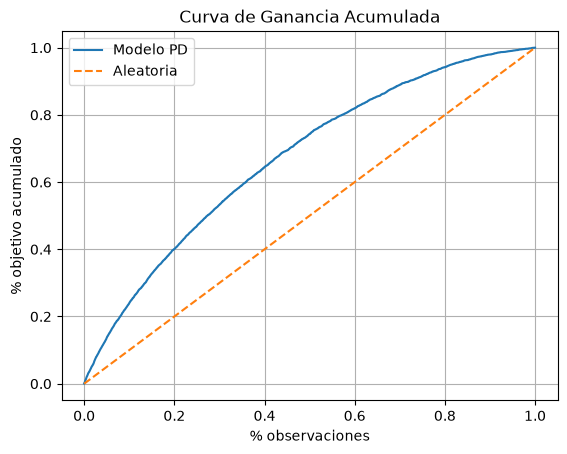

In [78]:
plot_gain_multi(y_val, [pred_val], labels=["Modelo PD"])

#### Lift Chart

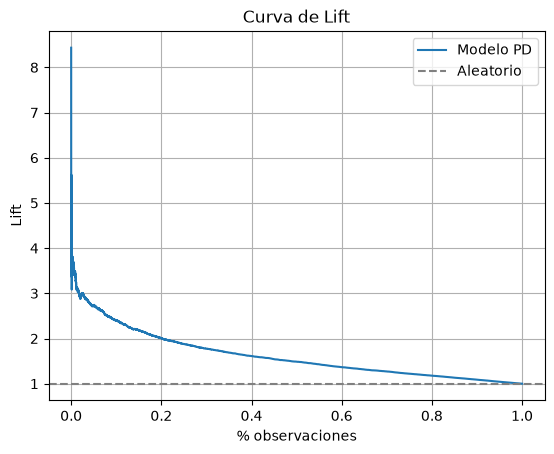

In [79]:
plot_lift_multi(y_val, [pred_val], labels=["Modelo PD"])

#### ROC Chart

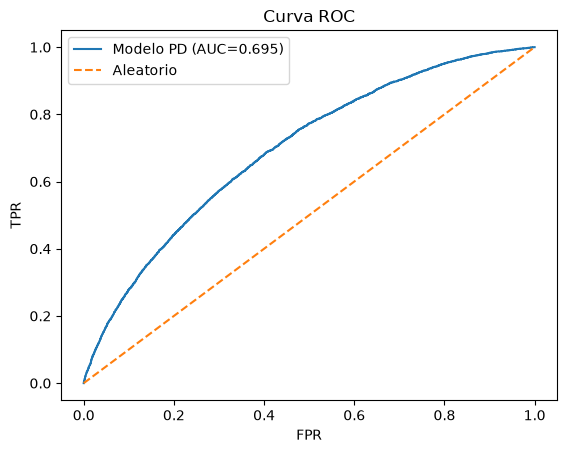

In [80]:
from utils import plot_roc_multi_np
plot_roc_multi_np(y_val, [pred_val], labels=["Modelo PD"])